### Demonstration of Locally Linear Embeddings

Author: Daniel Geelhoed,

Course: INFOMDW

We are going to repeat the experiment performed (but with another data shape) in the paper by Saul & Roweis [1] (page 2) by creating a swiss roll-shaped dataset and compressing its dimensionality.

[1] Roweis, S. T., & Saul, L. K. (2000). Nonlinear dimensionality reduction by locally linear embedding. science, 290(5500), 2323-2326. 

In [7]:
# Importing necessary packages. 
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.manifold import LocallyLinearEmbedding
from sklearn.datasets import make_swiss_roll
from sklearn.decomposition import PCA

In [ ]:
# Creating the dataset
n_rows = 2500
df, df_color = make_swiss_roll(n_samples = n_rows)
df = pd.DataFrame(df)
df

,0,1,2
0,6.335963,2.951466,1.553460
1,-9.049956,3.649999,-3.823556
2,12.034314,17.578505,4.765154
3,-2.447046,6.302917,7.782982
4,-6.185448,17.178477,6.047635
...,...,...,...
2495,6.592879,15.974365,-9.544402
2496,9.862244,2.674860,-6.773916
2497,-5.297069,1.454522,6.678936
2498,-8.758963,15.554573,2.598758


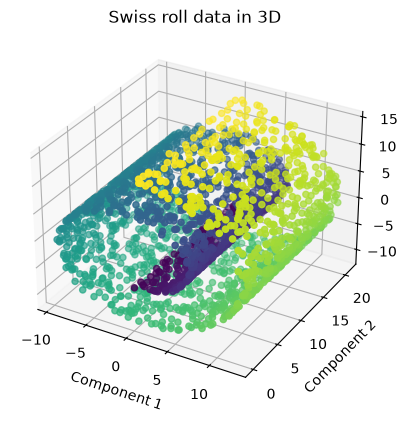

In [10]:
# Plotting the data in 3D
fig = plt.figure()
ax = plt.axes(projection = "3d")
ax.scatter3D(df[0], df[1], df[2], c = df_color, cmap = plt.cm.viridis)
plt.title("Swiss roll data in 3D")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.show()

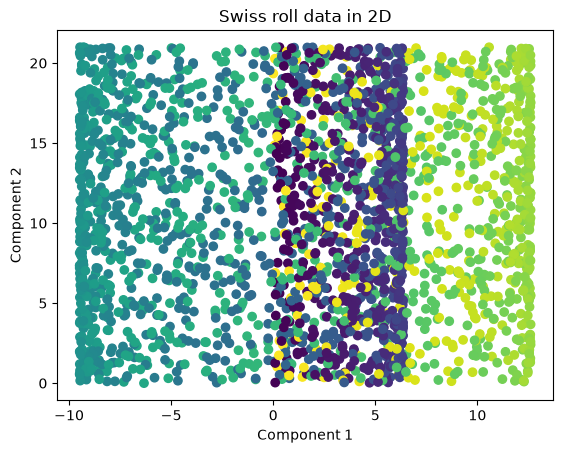

In [11]:
# Plotting the data in 2D. 
plt.figure()
plt.scatter(df[0], df[1], c = df_color, cmap = plt.cm.viridis)
plt.title("Swiss roll data in 2D")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.show()

As we can see from the above plots, it is not possible to discern the order of the colored data from a 2D plot. 
Now we will apply LLE to see if it can embed data in a way that it is plottable in 2D while it is still possible to discern to global structure as visible by color.

In this example, we will not go into details about the choice of K. We will asssume it to be 25 (1% of the dataset)

In [12]:
# Initializing LLE 
k = 25
lle = LocallyLinearEmbedding(n_neighbors = k, n_components = 2)

df_reduced = lle.fit_transform(df)
df_reduced = pd.DataFrame(df_reduced)

As we can see below, the LLE algorithm has mapped the threedimensional data into a twodimensional data structure. As visible by the color, it maintained the color structure that the original 3D also contained. Local optima have been reached, as neighbor proximity is maintained, but also the global structure has been kept.

It is as if the algorithm 'rolled out' the roll, which demonstrates its capability of mapping multidimensional data into two dimensions. 

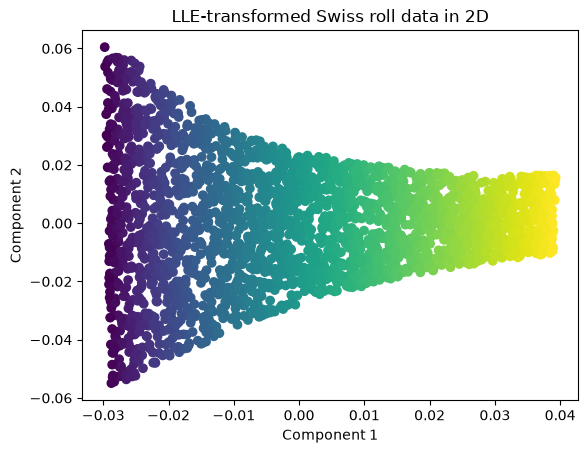

In [13]:
# Plotting the LLE-transformed data in 2D, using the same colors as the initial dataset.
plt.figure()
plt.scatter(df_reduced[0], df_reduced[1], c = df_color, cmap = plt.cm.viridis)
plt.title("LLE-transformed Swiss roll data in 2D")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.show()

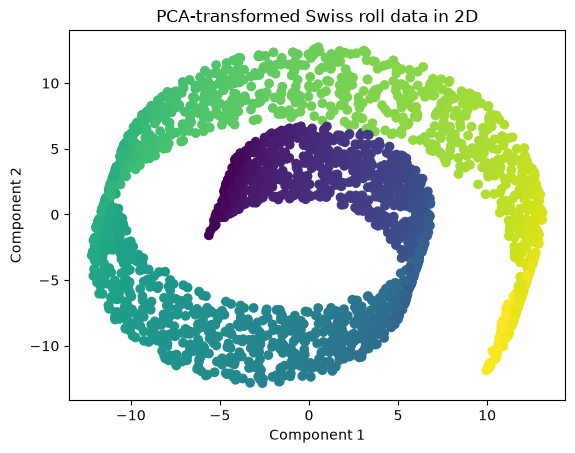

In [14]:
# For comparison, the PCA-embedded data is visualized below
pca = PCA(n_components = 2)
pca_df = pca.fit_transform(df)
pca_df = pd.DataFrame(pca_df)

plt.figure()
plt.scatter(pca_df[0], pca_df[1], c = df_color, cmap = plt.cm.viridis)
plt.title("PCA-transformed Swiss roll data in 2D")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.show()

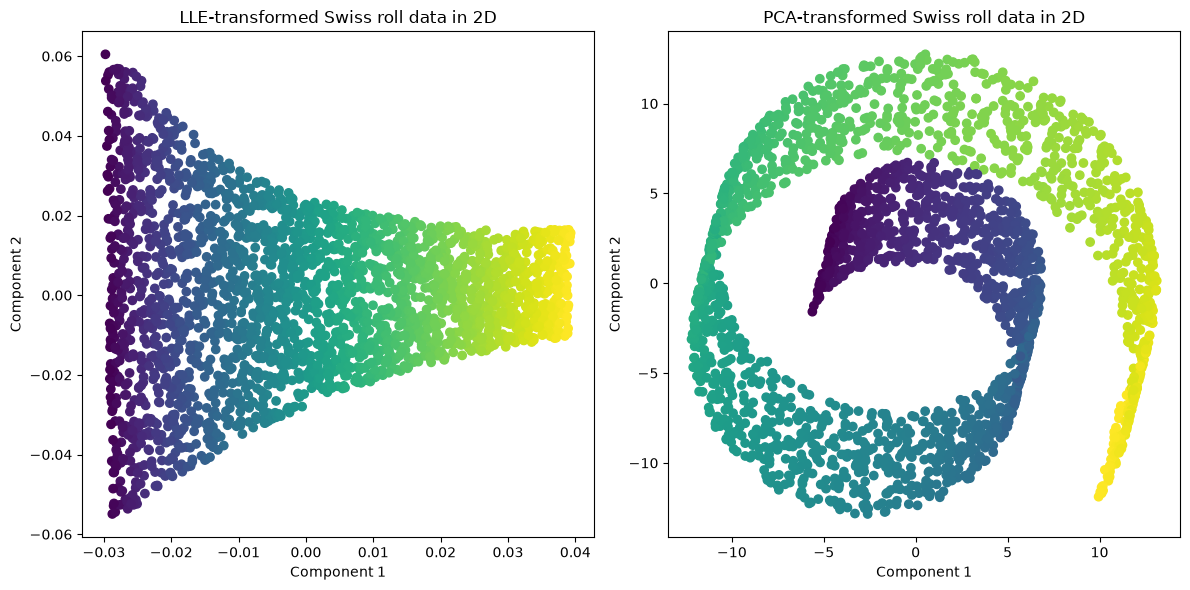

In [15]:
# Figure for in assignment report
plt.figure(figsize=(12, 6))

plt.subplot(121)
plt.scatter(df_reduced[0], df_reduced[1], c = df_color, cmap = plt.cm.viridis)
plt.title("LLE-transformed Swiss roll data in 2D")
plt.xlabel("Component 1")
plt.ylabel("Component 2")

plt.subplot(122)
plt.scatter(pca_df[0], pca_df[1], c = df_color, cmap = plt.cm.viridis)
plt.title("PCA-transformed Swiss roll data in 2D")
plt.xlabel("Component 1")
plt.ylabel("Component 2")

plt.tight_layout()
plt.show()

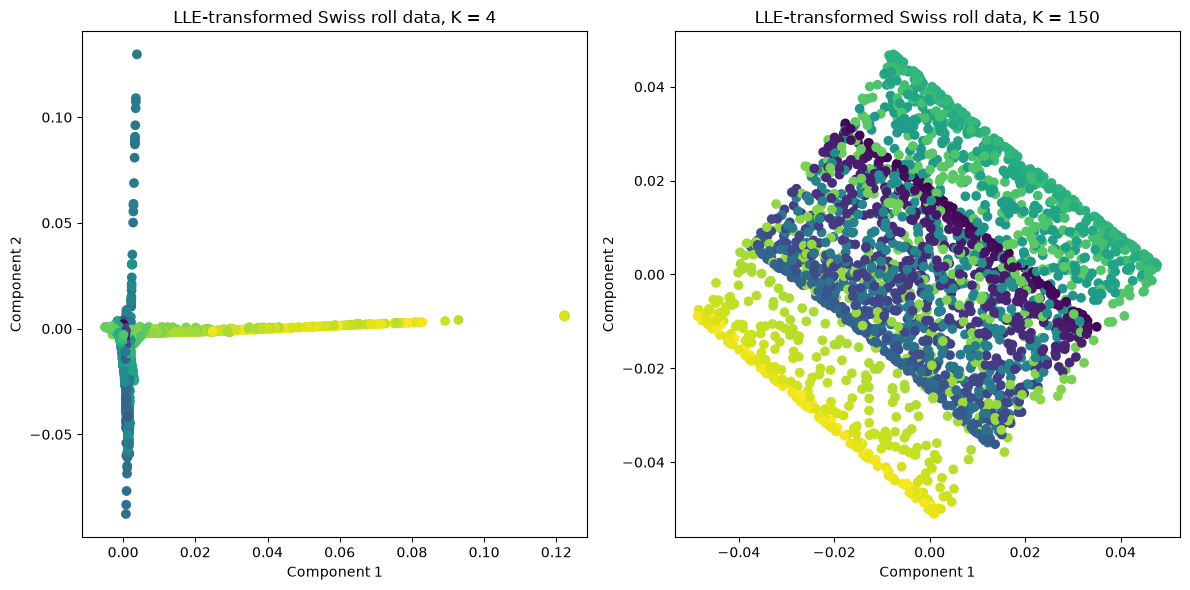

In [ ]:
# Visualizations for bad parameter usage (too many and too few neighbors)
lle_4 = LocallyLinearEmbedding(n_neighbors = 4, n_components = 2)
lle_150 = LocallyLinearEmbedding(n_neighbors = 150, n_components = 2)
df_4 = pd.DataFrame(lle_4.fit_transform(df))
df_150 = pd.DataFrame(lle_150.fit_transform(df))

plt.figure(figsize=(12, 6))

plt.subplot(121)
plt.scatter(df_4[0], df_4[1], c = df_color, cmap = plt.cm.viridis)
plt.title("LLE-transformed Swiss roll data, K = 4")
plt.xlabel("Component 1")
plt.ylabel("Component 2")

plt.subplot(122)
plt.scatter(df_150[0], df_150[1], c = df_color, cmap = plt.cm.viridis)
plt.title("LLE-transformed Swiss roll data, K = 150")
plt.xlabel("Component 1")
plt.ylabel("Component 2")

plt.tight_layout()
plt.show()